# Classifying emails with BERT and KNN

**Question:** How does the way we represent an email affect classification?

We use only the first **1,000 rows** of `Phishing_Email.csv` and compare four representations:

| Experiment | Representation | Numbers per email |
|---|---|---:|
| Base model | BERT CLS token | 768 |
| Bonus 1 | Average of BERT token embeddings | 768 |
| Bonus 2 | CLS reduced with PCA | 2 |
| Bonus 2 | CLS reduced with UMAP | 2 |

An **embedding** is a list of numbers representing text. **KNN** predicts a label by looking at the labels of the five closest training emails.

Run the cells from top to bottom. Each step produces a small output you can inspect. The worked examples in Step 4 explain the embeddings. Steps 5–8 contain both bonus sections, test results, and conclusions.

This walkthrough adapts the teaching approach of the supplied **BERT_Word_Embeddings_v2 (1).ipynb**: inspect the tokens, examine the hidden-state shapes, and then build an email vector. The examples below are illustrative and are not added to the email dataset.

## 1. Set up the experiment

Use Python 3.12 with the supplied dependencies. If needed, install them in your notebook environment with `%pip install -r requirements.txt`.

All experiments use the same split and the same KNN settings. This lets us compare the effect of changing the representation.

In [ ]:
import os
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from transformers import BertTokenizerFast, BertModel
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (f1_score, accuracy_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from umap import UMAP

%matplotlib inline

In [2]:
# Change CSV_PATH if you move the dataset.
CSV_PATH = Path(os.environ.get(
    "PHISHING_CSV",
    "/Users/sovinbirla/UChicago/Generative AI/Assignment 1/Phishing_Email.csv"
))
SEED = 42
MAX_TOKENS = 512
BATCH_SIZE = 8
MODEL_NAME = "google-bert/bert-base-uncased"
MODEL_REVISION = "86b5e0934494bd15c9632b12f734a8a67f723594"

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

## 2. Read only the first 1,000 rows

The row limit is applied **before** cleaning. If a row has no email text, we exclude it without taking a replacement from later in the file.

We use `Email Text` as the input and `Email Type` as the label. The unnamed index column is ignored.

In [3]:
raw = pd.read_csv(CSV_PATH, nrows=1000, keep_default_na=False)
raw["source_row"] = np.arange(1, len(raw) + 1)
raw["Email Text"] = raw["Email Text"].str.strip()
raw["Email Type"] = raw["Email Type"].str.strip()

valid = (
    raw["Email Text"].ne("")
    & raw["Email Type"].isin(["Safe Email", "Phishing Email"])
)
emails = raw.loc[valid].copy().reset_index(drop=True)

print(f"Loaded: {len(raw)} rows")
print(f"Excluded: {len(raw) - len(emails)} empty or invalid rows")
print(f"Used: {len(emails)} emails")

Loaded: 1000 rows
Excluded: 2 empty or invalid rows
Used: 998 emails


In [4]:
# Encode phishing as 1 so it is the positive class for F1.
label_codes = {"Safe Email": 0, "Phishing Email": 1}
y = emails["Email Type"].map(label_codes).to_numpy()
texts = emails["Email Text"].tolist()

class_counts = emails["Email Type"].value_counts().rename("Emails")
display(class_counts.to_frame())

,Emails
Email Type,
Safe Email,596
Phishing Email,402


## 3. Tokenize the emails and create the train/test split

BERT breaks text into **tokens**: words, word pieces, and special markers. It accepts at most 512 tokens, including CLS and SEP. Longer emails are represented by their first 510 content tokens.

The next cell chooses the local BERT download when available. On another computer, it downloads the same pinned model revision.

In [5]:
local_model = Path.cwd().parent / "work" / "bert-base-uncased"
model_source = str(local_model) if local_model.is_dir() else MODEL_NAME
model_settings = {
    "revision": MODEL_REVISION,
    "cache_dir": str(Path.cwd().parent / "work" / "huggingface"),
}
tokenizer = BertTokenizerFast.from_pretrained(model_source, **model_settings)

encoded = tokenizer(
    texts, truncation=True, max_length=MAX_TOKENS, padding=False
)
full_tokens = tokenizer(texts, truncation=False, padding=False, verbose=False)
token_counts = np.array([len(ids) for ids in full_tokens["input_ids"]])
print(f"Emails truncated to 512 tokens: {(token_counts > MAX_TOKENS).sum()}")

Emails truncated to 512 tokens: 238


**Why group duplicates?** If the same email appears in training and testing, the test score can be misleading. We keep identical BERT inputs together, including inputs that become identical after lowercasing or truncation.

The small helper below assigns identical token sequences the same identifier.

In [ ]:
def input_signature(token_ids):
    token_bytes = np.asarray(token_ids, dtype=np.int32).tobytes()
    return hashlib.sha256(token_bytes).hexdigest()

signatures = [input_signature(ids) for ids in encoded["input_ids"]]
groups = pd.factorize(signatures, sort=False)[0]

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(np.zeros(len(y)), y, groups))

assert set(groups[train_idx]).isdisjoint(groups[test_idx])
y_train, y_test = y[train_idx], y[test_idx]
print(f"Training: {len(train_idx)} emails | Testing: {len(test_idx)} emails")

: 

In [7]:
partition = np.full(len(emails), "Train", dtype=object)
partition[test_idx] = "Test"
display(pd.crosstab(partition, emails["Email Type"]).reindex(["Train", "Test"]))

Email Type,Phishing Email,Safe Email
row_0,,
Train,318,480
Test,84,116


This is **one held-out split**, taken from a five-fold splitter. The reported scores are not averages over five folds. We use this same split for all four experiments.

The source has one group with conflicting labels. We keep the labels as supplied and keep that group within one partition.

## 4. Create the two BERT representations

BERT produces 768 numbers for every token. We use its **final hidden layer**, with the pretrained model frozen in evaluation mode.

| Method | How we create one vector per email |
|---|---|
| **CLS** | Take the first token's vector: `hidden[:, 0, :]` |
| **Average** | Average every non-padding token's vector, including CLS and SEP |

Padding makes emails in a batch the same length. It is not email content, so the attention mask excludes it from the average.

The reference notebook illustrates averaging the **second-to-last layer**. Here, both CLS and averaging use the **same final layer**, so Bonus 1 changes only the pooling method. BERT stays frozen. We fit KNN using the embeddings and labels.

In [8]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

model = BertModel.from_pretrained(
    model_source, use_safetensors=True, **model_settings
).to(device).eval()
print(f"BERT runs locally on: {device}")

BERT runs locally on: cpu


### 4.1. See what BERT receives

Start with a short sentence containing two meanings of **bank**. The tokenizer adds CLS and SEP automatically.

Each **token ID** identifies a vocabulary entry. The **attention mask** is 1 for real tokens and 0 for padding. The **segment ID** is 0 throughout this single-sequence example.

In [9]:
demo_text = "Please contact the bank. We walked along the river bank."
demo_inputs = tokenizer(demo_text, return_tensors="pt")
demo_ids = demo_inputs["input_ids"][0].tolist()
demo_tokens = tokenizer.convert_ids_to_tokens(demo_ids)

display(pd.DataFrame({
    "Position": range(len(demo_tokens)),
    "Token": demo_tokens,
    "Token ID": demo_ids,
    "Attention mask": demo_inputs["attention_mask"][0].tolist(),
    "Segment ID": demo_inputs["token_type_ids"][0].tolist(),
}).style.hide(axis="index"))

Position,Token,Token ID,Attention mask,Segment ID
0,[CLS],101,1,0
1,please,3531,1,0
2,contact,3967,1,0
3,the,1996,1,0
4,bank,2924,1,0
5,.,1012,1,0
6,we,2057,1,0
7,walked,2939,1,0
8,along,2247,1,0
9,the,1996,1,0


Some words split into smaller pieces. A token starting with `##` continues the previous word. The next example lets you inspect WordPiece tokenization directly, as in the reference notebook.

In [10]:
word_example = "Here is the sentence I want embeddings for."
pieces = tokenizer.tokenize(word_example)
print("Word pieces:", pieces)

Word pieces: ['here', 'is', 'the', 'sentence', 'i', 'want', 'em', '##bed', '##ding', '##s', 'for', '.']


### 4.2. Run BERT once and inspect the shapes

For this small example, request every hidden layer. Production email extraction uses only the final layer to save memory.

The output contains **13 states**: the initial embedding state plus the outputs from **12 transformer layers**. Each state has shape `(batch, tokens, features)`.

In [11]:
demo_on_device = {key: value.to(device) for key, value in demo_inputs.items()}
with torch.inference_mode():
    demo_outputs = model(**demo_on_device, output_hidden_states=True)

hidden_states = tuple(layer.cpu() for layer in demo_outputs.hidden_states)
display(pd.DataFrame({
    "Item": ["Hidden states", "Batch size", "Tokens", "Features per token"],
    "Value": [len(hidden_states), hidden_states[-1].shape[0],
              hidden_states[-1].shape[1], hidden_states[-1].shape[2]],
}).style.hide(axis="index"))

Item,Value
Hidden states,13
Batch size,1
Tokens,14
Features per token,768


Like the reference, we can stack and rearrange the layers. This changes how we index the numbers; it does not change their values.

In [12]:
# First: (layers, batch, tokens, features).
stacked_layers = torch.stack(hidden_states, dim=0)
print("Stacked layers:", tuple(stacked_layers.shape))

# There is only one sentence, so remove its batch dimension.
without_batch = stacked_layers.squeeze(1)
print("Without batch:", tuple(without_batch.shape))

# Put tokens first so we can inspect all layers for one token.
by_token = without_batch.permute(1, 0, 2)
print("Tokens first:", tuple(by_token.shape))

Stacked layers: (13, 1, 14, 768)
Without batch: (13, 14, 768)
Tokens first: (14, 13, 768)


### 4.3. The same word can have different vectors

Both occurrences of **bank** have the same vocabulary ID. Their final-layer vectors differ because BERT processes each occurrence in context. We display only the first five values; every complete vector has 768 values.

In [13]:
final_token_vectors = hidden_states[-1][0]
bank_positions = [i for i, token in enumerate(demo_tokens) if token == "bank"]
bank_preview = pd.DataFrame(
    final_token_vectors[bank_positions, :5].numpy(),
    index=["Financial bank", "River bank"],
    columns=[f"Value {i}" for i in range(1, 6)],
)
print("Vocabulary IDs:", [demo_ids[i] for i in bank_positions])
display(bank_preview.style.format("{:.4f}"))

Vocabulary IDs: [2924, 2924]


,Value 1,Value 2,Value 3,Value 4,Value 5
Financial bank,-0.0400,-0.6480,-0.0300,-0.0019,0.4596
River bank,0.2028,-0.3656,-0.2009,-0.1376,-0.0474


### 4.4. Build CLS and average vectors for one sentence

CLS takes the first token's vector. Averaging combines the token vectors. This sentence has no padding, so a direct mean is valid. Both methods produce one 768-dimensional vector.

This is the same pooling choice we will compare across the emails.

In [14]:
demo_cls = final_token_vectors[0]
demo_average = final_token_vectors.mean(dim=0)

print("CLS shape:", tuple(demo_cls.shape))
print("Average shape:", tuple(demo_average.shape))
display(pd.DataFrame(
    [demo_cls[:5].numpy(), demo_average[:5].numpy()],
    index=["CLS", "Average of all tokens"],
    columns=[f"Value {i}" for i in range(1, 6)],
).style.format("{:.4f}"))

CLS shape: (768,)
Average shape: (768,)


,Value 1,Value 2,Value 3,Value 4,Value 5
CLS,0.0817,-0.0798,-0.2651,0.0543,-0.1790
Average of all tokens,0.1902,-0.1547,-0.0997,0.1501,0.0887


### 4.5. Why the attention mask matters for averaging

When two texts have different lengths, the tokenizer adds padding to the shorter one. Averaging padding would make the representation depend on how much padding the batch needs.

We multiply by the mask, add only real-token vectors, and divide by the number of real tokens. CLS and SEP are included because they have mask value 1.

In [15]:
padding_texts = ["Verify your account.", "Please verify your account details today."]
padding_inputs = tokenizer(padding_texts, padding=True, return_tensors="pt")
display(pd.DataFrame({
    "Text": padding_texts,
    "Tokens": [tokenizer.convert_ids_to_tokens(ids.tolist())
               for ids in padding_inputs["input_ids"]],
    "Mask": padding_inputs["attention_mask"].tolist(),
}).style.hide(axis="index"))

Text,Tokens,Mask
Verify your account.,"['[CLS]', 'verify', 'your', 'account', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]']","[1, 1, 1, 1, 1, 1, 0, 0, 0]"
Please verify your account details today.,"['[CLS]', 'please', 'verify', 'your', 'account', 'details', 'today', '.', '[SEP]']","[1, 1, 1, 1, 1, 1, 1, 1, 1]"


In [16]:
padding_on_device = {key: value.to(device) for key, value in padding_inputs.items()}
with torch.inference_mode():
    padding_hidden = model(**padding_on_device).last_hidden_state.cpu()

mask = padding_inputs["attention_mask"].unsqueeze(-1).to(padding_hidden.dtype)
masked_average = (padding_hidden * mask).sum(1) / mask.sum(1)
print("Two texts become two vectors:", tuple(masked_average.shape))

real_tokens = padding_inputs["attention_mask"][0].bool()
assert torch.allclose(masked_average[0], padding_hidden[0, real_tokens].mean(0))
print("Check passed: padding is excluded from the average.")

Two texts become two vectors: (2, 768)
Check passed: padding is excluded from the average.


### 4.6. Apply those two methods to the email dataset

The helper below performs exactly the masked average just demonstrated. The batch loop stores a CLS vector and an average vector for each retained email.

In [17]:
def average_tokens(hidden, attention_mask):
    mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
    token_sum = (hidden * mask).sum(dim=1)
    token_count = mask.sum(dim=1)
    return token_sum / token_count

n_emails = len(emails)
cls_embeddings = np.empty((n_emails, 768), dtype=np.float32)
mean_embeddings = np.empty_like(cls_embeddings)

# Process similar-length emails together to reduce padding.
order = np.argsort([len(ids) for ids in encoded["input_ids"]], kind="stable")

The next cell processes eight emails at a time. It stores CLS and average embeddings in the original row order. This is the main computation and can take a few minutes on a CPU.

In [18]:
with torch.inference_mode():
    for start in range(0, n_emails, BATCH_SIZE):
        indices = order[start:start + BATCH_SIZE]
        items = [{key: encoded[key][i] for key in encoded} for i in indices]
        batch = tokenizer.pad(items, padding=True, return_tensors="pt")
        batch = {key: value.to(device) for key, value in batch.items()}

        hidden = model(**batch).last_hidden_state
        cls_embeddings[indices] = hidden[:, 0, :].cpu().numpy()
        mean_embeddings[indices] = average_tokens(
            hidden, batch["attention_mask"]
        ).cpu().numpy()

        if (start // BATCH_SIZE + 1) % 40 == 0:
            print(f"Processed {min(start + BATCH_SIZE, n_emails)} / {n_emails}")

print("Both embeddings are ready.")

Processed 320 / 998
Processed 640 / 998
Processed 960 / 998
Both embeddings are ready.


In [19]:
assert np.isfinite(cls_embeddings).all()
assert np.isfinite(mean_embeddings).all()
display(pd.DataFrame({
    "Representation": ["CLS", "Average tokens"],
    "Emails": [len(cls_embeddings), len(mean_embeddings)],
    "Dimensions": [cls_embeddings.shape[1], mean_embeddings.shape[1]],
}))

cls_train, cls_test = cls_embeddings[train_idx], cls_embeddings[test_idx]
mean_train, mean_test = mean_embeddings[train_idx], mean_embeddings[test_idx]
del model  # Embedding extraction is finished.

,Representation,Emails,Dimensions
0,CLS,998,768
1,Average tokens,998,768


## 5. Base model and Bonus 1: CLS versus average tokens

Each classifier uses **K=5**, **Euclidean distance**, and **uniform voting**. The test emails are used only for evaluation.

We report two F1 scores, on a scale from 0 to 1:

- **Phishing F1:** balances precision and recall for phishing emails. Higher is better.
- **Macro F1:** the average of safe-email F1 and phishing-email F1, giving both classes equal weight.

For phishing F1, `F1 = 2 × TP / (2 × TP + FP + FN)`, where TP means correctly detected phishing, FP means safe emails flagged as phishing, and FN means missed phishing emails.

In [20]:
def evaluate_knn(name, x_train, x_test):
    classifier = KNeighborsClassifier(
        n_neighbors=5, weights="uniform", metric="euclidean",
        algorithm="brute", n_jobs=1
    )
    classifier.fit(x_train, y_train)
    predicted = classifier.predict(x_test)
    scores = {
        "Representation": name,
        "Dimensions": x_train.shape[1],
        "Phishing F1": f1_score(y_test, predicted, pos_label=1),
        "Macro F1": f1_score(y_test, predicted, average="macro"),
        "Accuracy": accuracy_score(y_test, predicted),
    }
    return scores, predicted

In [21]:
def show_test_results(name, predicted):
    display(Markdown(f"### Test results: {name}"))
    matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
    display(pd.DataFrame(
        matrix, index=["Actual safe", "Actual phishing"],
        columns=["Predicted safe", "Predicted phishing"],
    ))
    report = classification_report(
        y_test, predicted, labels=[0, 1],
        target_names=["Safe Email", "Phishing Email"],
        output_dict=True, zero_division=0,
    )
    report_table = pd.DataFrame(report).T.loc[
        ["Safe Email", "Phishing Email", "macro avg"],
        ["precision", "recall", "f1-score", "support"],
    ]
    display(report_table.style.format({
        "precision": "{:.4f}", "recall": "{:.4f}",
        "f1-score": "{:.4f}", "support": "{:.0f}",
    }))

In [22]:
cls_score, cls_predictions = evaluate_knn("CLS", cls_train, cls_test)
mean_score, mean_predictions = evaluate_knn("Average tokens", mean_train, mean_test)

bonus1 = pd.DataFrame([cls_score, mean_score])
display(bonus1.style.format({
    "Phishing F1": "{:.4f}", "Macro F1": "{:.4f}", "Accuracy": "{:.1%}"
}).hide(axis="index"))

Representation,Dimensions,Phishing F1,Macro F1,Accuracy
CLS,768,0.8603,0.8736,87.5%
Average tokens,768,0.8667,0.8788,88.0%


### Read the confusion matrix

Rows show the actual class; columns show the predicted class. The diagonal entries are correct predictions. **Actual phishing / predicted safe** counts missed phishing emails. **Actual safe / predicted phishing** counts false alarms.

The reports also show precision, recall, F1, and support (the number of test emails in each actual class).

In [23]:
show_test_results("CLS (768D)", cls_predictions)

### Test results: CLS (768D)

,Predicted safe,Predicted phishing
Actual safe,98,18
Actual phishing,7,77


,precision,recall,f1-score,support
Safe Email,0.9333,0.8448,0.8869,116
Phishing Email,0.8105,0.9167,0.8603,84
macro avg,0.8719,0.8807,0.8736,200


In [24]:
show_test_results("Average tokens (768D)", mean_predictions)

### Test results: Average tokens (768D)

,Predicted safe,Predicted phishing
Actual safe,98,18
Actual phishing,6,78


,precision,recall,f1-score,support
Safe Email,0.9423,0.8448,0.8909,116
Phishing Email,0.8125,0.9286,0.8667,84
macro avg,0.8774,0.8867,0.8788,200


In [25]:
change = mean_score["Phishing F1"] - cls_score["Phishing F1"]
display(Markdown(
    f"**Bonus 1 finding:** Average-token phishing F1 is "
    f"**{mean_score['Phishing F1']:.4f}**, compared with "
    f"**{cls_score['Phishing F1']:.4f}** for CLS. "
    f"The difference is **{change:+.4f}** on this split."
))

**Bonus 1 finding:** Average-token phishing F1 is **0.8667**, compared with **0.8603** for CLS. The difference is **+0.0063** on this split.

CLS uses one contextual token vector. Averaging combines contextual information across the retained tokens. The small score difference here does not establish that one method is consistently better across other splits.

## 6. Bonus 2: reduce the original CLS vectors to two dimensions

Both PCA and UMAP start with the **original 768-dimensional CLS embeddings**. UMAP is applied directly to CLS, rather than to the PCA output.

| Technique | Main idea |
|---|---|
| **PCA** | A linear projection that keeps as much overall variation as possible |
| **UMAP** | A nonlinear map that tries to preserve neighborhood relationships |

We fit each reducer on training emails and transform test emails using that fitted reducer. No feature scaling is applied, and UMAP does not receive labels.

### PCA

Keep two components. The explained variance tells us how much of the training vectors' total variation those components capture.

In [26]:
pca = PCA(n_components=2, svd_solver="full", random_state=SEED)
pca_train = pca.fit_transform(cls_train)
pca_test = pca.transform(cls_test)

variance_retained = pca.explained_variance_ratio_.sum()
print(f"Variance retained by two PCA components: {variance_retained:.2%}")

pca_score, pca_predictions = evaluate_knn("CLS + PCA", pca_train, pca_test)

Variance retained by two PCA components: 21.51%


In [27]:
show_test_results("CLS + PCA (2D)", pca_predictions)

### Test results: CLS + PCA (2D)

,Predicted safe,Predicted phishing
Actual safe,82,34
Actual phishing,36,48


,precision,recall,f1-score,support
Safe Email,0.6949,0.7069,0.7009,116
Phishing Email,0.5854,0.5714,0.5783,84
macro avg,0.6401,0.6392,0.6396,200


### UMAP

Use 15 neighbors and a minimum distance of 0.1. These are fixed settings. Seed 42 makes the stochastic reduction repeatable in this environment.

In [28]:
umap = UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=SEED,
    transform_seed=SEED,
    n_jobs=1,
)
umap_train = umap.fit_transform(cls_train)
umap_test = umap.transform(cls_test)

umap_score, umap_predictions = evaluate_knn("CLS + UMAP", umap_train, umap_test)

In [29]:
show_test_results("CLS + UMAP (2D)", umap_predictions)

### Test results: CLS + UMAP (2D)

,Predicted safe,Predicted phishing
Actual safe,93,23
Actual phishing,18,66


,precision,recall,f1-score,support
Safe Email,0.8378,0.8017,0.8194,116
Phishing Email,0.7416,0.7857,0.7630,84
macro avg,0.7897,0.7937,0.7912,200


## 7. Compare all four results

The table uses the same 200 test emails for every representation. The 768D CLS row is the baseline for the dimensionality-reduction comparison.

In [30]:
results = pd.DataFrame([cls_score, mean_score, pca_score, umap_score])
display(results.style.format({
    "Phishing F1": "{:.4f}", "Macro F1": "{:.4f}", "Accuracy": "{:.1%}"
}).hide(axis="index"))

Representation,Dimensions,Phishing F1,Macro F1,Accuracy
CLS,768,0.8603,0.8736,87.5%
Average tokens,768,0.8667,0.8788,88.0%
CLS + PCA,2,0.5783,0.6396,65.0%
CLS + UMAP,2,0.7630,0.7912,79.5%


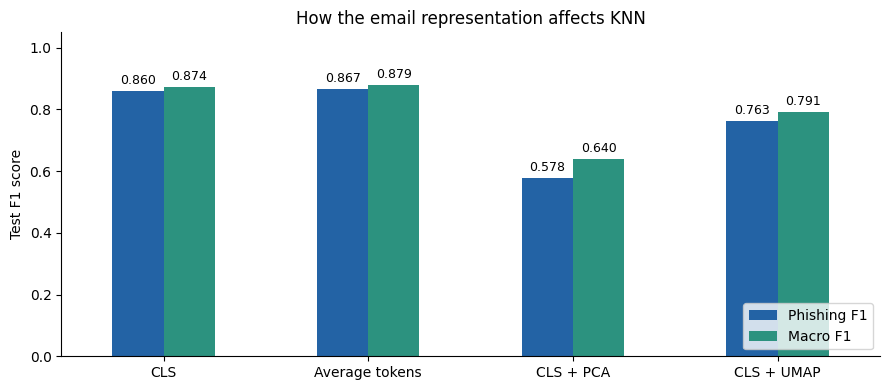

In [31]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_data = results.set_index("Representation")[["Phishing F1", "Macro F1"]]
plot_data.plot.bar(ax=ax, color=["#2363a5", "#2c927f"], rot=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Test F1 score")
ax.set_xlabel("")
ax.set_title("How the email representation affects KNN")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### Compare errors across the four classifiers

Each panel uses the same class order: safe first, phishing second. Read the lower-left cell to see how many phishing emails that method missed.

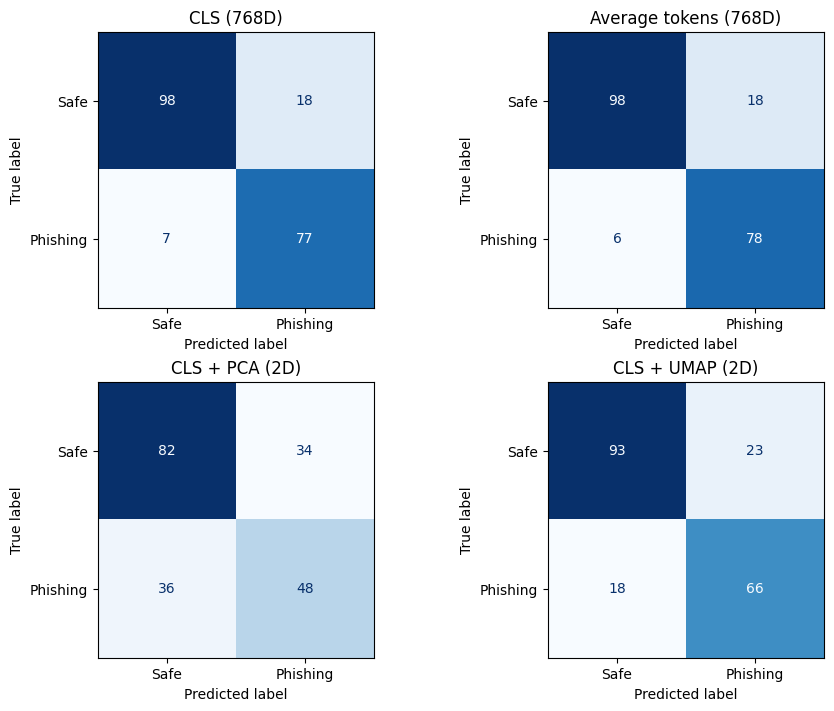

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")
test_predictions = {
    "CLS (768D)": cls_predictions,
    "Average tokens (768D)": mean_predictions,
    "CLS + PCA (2D)": pca_predictions,
    "CLS + UMAP (2D)": umap_predictions,
}
for ax, (name, predicted) in zip(axes.flat, test_predictions.items()):
    matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Safe", "Phishing"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
plt.show()

### What do the two-dimensional maps look like?

Dots are training emails. Crosses are transformed test emails. Blue means safe and orange means phishing. Colors use the actual labels for visualization only.

Overlapping classes can make KNN classification harder. Plot distances have different meanings in PCA and UMAP, so compare the classification scores rather than judging by visual separation alone.

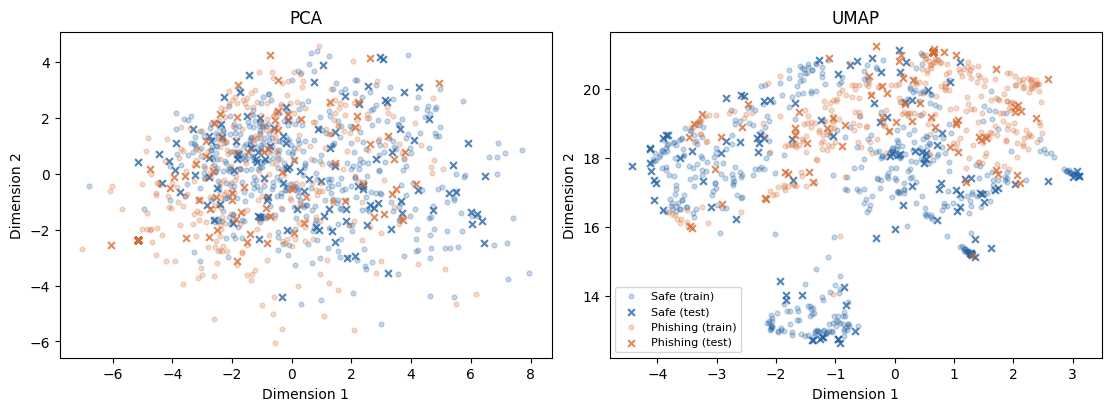

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
projections = {"PCA": (pca_train, pca_test), "UMAP": (umap_train, umap_test)}

for ax, (name, (train_points, test_points)) in zip(axes, projections.items()):
    for label, color, text in [(0, "#2363a5", "Safe"), (1, "#d76c36", "Phishing")]:
        ax.scatter(*train_points[y_train == label].T, s=12, color=color,
                   alpha=0.25, label=f"{text} (train)")
        ax.scatter(*test_points[y_test == label].T, s=24, color=color,
                   marker="x", alpha=0.8, label=f"{text} (test)")
    ax.set(title=name, xlabel="Dimension 1", ylabel="Dimension 2")

axes[1].legend(fontsize=8)
plt.show()

## 8. Conclusions

Read the findings below together with the table. A higher F1 on this one split does not establish a general ranking across datasets or other parameter choices.

In [34]:
best = results.loc[results["Phishing F1"].idxmax()]
baseline_f1 = cls_score["Phishing F1"]
display(Markdown(f"""**Highest phishing F1:** {best['Representation']} ({best['Phishing F1']:.4f}).

**Bonus 1:** Average tokens scored {mean_score['Phishing F1']:.4f}, versus {baseline_f1:.4f} for CLS.

**Bonus 2:** PCA scored {pca_score['Phishing F1']:.4f} and UMAP scored {umap_score['Phishing F1']:.4f}, versus {baseline_f1:.4f} for original CLS.

Both two-dimensional representations scored lower than the 768-dimensional CLS baseline on this split. UMAP scored higher than PCA.

PCA retained {variance_retained:.2%} of training variance. {(token_counts > MAX_TOKENS).sum()} emails were truncated, so these results use only the retained portion of longer emails.
"""))

**Highest phishing F1:** Average tokens (0.8667).

**Bonus 1:** Average tokens scored 0.8667, versus 0.8603 for CLS.

**Bonus 2:** PCA scored 0.5783 and UMAP scored 0.7630, versus 0.8603 for original CLS.

Both two-dimensional representations scored lower than the 768-dimensional CLS baseline on this split. UMAP scored higher than PCA.

PCA retained 21.51% of training variance. 238 emails were truncated, so these results use only the retained portion of longer emails.


## Check against the saved experiment

This optional check confirms that the reorganized notebook reproduces the earlier scores and predictions. It runs when the supplied results files are beside the notebook.

In [35]:
saved_file = Path("test_predictions.csv")
if saved_file.exists():
    saved = pd.read_csv(saved_file).set_index("source_row")
    row_ids = emails.iloc[test_idx]["source_row"].to_numpy()
    predictions = {
        "CLS (768D)": cls_predictions,
        "Average tokens (768D)": mean_predictions,
        "CLS + PCA (2D)": pca_predictions,
        "CLS + UMAP (2D)": umap_predictions,
    }
    for name, predicted in predictions.items():
        expected = saved.loc[row_ids, name].map(label_codes).to_numpy()
        assert np.array_equal(predicted, expected), name
    print("All four models reproduce the saved test predictions.")

All four models reproduce the saved test predictions.


## References and supporting files

- [BERT model](https://huggingface.co/google-bert/bert-base-uncased) and [BERT output documentation](https://huggingface.co/docs/transformers/model_doc/bert)
- [UMAP: transforming new data](https://umap-learn.readthedocs.io/en/latest/transform.html)
- [F1 score definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)

The accompanying `report.md` explains the method in prose. `f1_results.csv` contains the full score table, and `test_predictions.csv` contains each test email's predictions. `bert_knn.py` is the command-line version with caching and export options.

**Teaching reference:** Chris McCormick and Nick Ryan (2019), *BERT Word Embeddings Tutorial*, supplied as `BERT_Word_Embeddings_v2 (1).ipynb`. [Original tutorial](https://mccormickml.com/2019/05/14/BERT-word-embeddings-tutorial/). Token inspection, hidden-state stacking, and the contextual word example are adapted from its approach. This submission uses automatic single-sequence segment IDs and a consistent final-layer pooling comparison.